In [ ]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import copy
import os
import csv
import re
import time

from collections import Counter

from torch.utils.data import TensorDataset, DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

torch.manual_seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
df = pd.read_csv("URLDataset.csv")

In [ ]:
df.columns

Index(['url', 'url_len', 'dom', 'dom_len', 'is_ip', 'tld', 'tld_len',
       'subdom_cnt', 'letter_cnt', 'digit_cnt', 'special_cnt', 'eq_cnt',
       'qm_cnt', 'amp_cnt', 'dot_cnt', 'dash_cnt', 'under_cnt', 'letter_ratio',
       'digit_ratio', 'spec_ratio', 'is_https', 'slash_cnt', 'entropy',
       'path_len', 'query_len', 'label'],
      dtype='object')

In [ ]:
df.shape

(116600, 26)

In [ ]:
df.head()

,url,url_len,dom,dom_len,is_ip,tld,tld_len,subdom_cnt,letter_cnt,digit_cnt,...,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
0,https://www.rmit.edu.au/,24,rmit.edu.au,11,0,edu.au,6,1,17,0,...,0,0.708333,0.0,0.291667,1,3,3.709148,1,0,0
1,http://www.latrobe.edu.au/,26,latrobe.edu.au,14,0,edu.au,6,1,19,0,...,0,0.730769,0.0,0.269231,0,3,3.738149,1,0,0
2,https://www.cqu.edu.au/,23,cqu.edu.au,10,0,edu.au,6,1,16,0,...,0,0.695652,0.0,0.304348,1,3,3.609668,1,0,0
3,http://bond.edu.au/,19,bond.edu.au,11,0,edu.au,6,0,13,0,...,0,0.684211,0.0,0.315789,0,3,3.576618,1,0,0
4,http://www.csu.edu.au/,22,csu.edu.au,10,0,edu.au,6,1,15,0,...,0,0.681818,0.0,0.318182,0,3,3.503998,1,0,0


In [ ]:
df = df.drop(columns=["url", "dom", "tld"])

In [ ]:
df.isnull().sum()

,0
url_len,0
dom_len,0
is_ip,0
tld_len,0
subdom_cnt,0
letter_cnt,0
digit_cnt,0
special_cnt,0
eq_cnt,0
qm_cnt,0


In [ ]:
df.duplicated().sum()

np.int64(62183)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.shape

(54417, 23)

In [ ]:
df.head()

,url_len,dom_len,is_ip,tld_len,subdom_cnt,letter_cnt,digit_cnt,special_cnt,eq_cnt,qm_cnt,...,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
0,24,11,0,6,1,17,0,7,0,0,...,0,0.708333,0.0,0.291667,1,3,3.709148,1,0,0
1,26,14,0,6,1,19,0,7,0,0,...,0,0.730769,0.0,0.269231,0,3,3.738149,1,0,0
2,23,10,0,6,1,16,0,7,0,0,...,0,0.695652,0.0,0.304348,1,3,3.609668,1,0,0
3,19,11,0,6,0,13,0,6,0,0,...,0,0.684211,0.0,0.315789,0,3,3.576618,1,0,0
4,22,10,0,6,1,15,0,7,0,0,...,0,0.681818,0.0,0.318182,0,3,3.503998,1,0,0


In [ ]:
df.describe()

,url_len,dom_len,is_ip,tld_len,subdom_cnt,letter_cnt,digit_cnt,special_cnt,eq_cnt,qm_cnt,...,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
count,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,...,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000
mean,42.663028,13.717294,0.000221,3.425988,0.886561,32.699083,1.860816,8.103130,0.165739,0.078358,...,0.113770,0.765087,0.023317,0.211595,0.517136,3.509289,4.030527,11.985538,3.380580,0.237242
std,40.364562,5.813590,0.014848,1.607535,0.538245,30.584913,8.481261,5.503192,0.707213,0.280710,...,0.701191,0.067823,0.062496,0.052026,0.499711,1.223270,0.406561,24.234633,28.088924,0.425396
min,12.000000,4.000000,0.000000,0.000000,0.000000,4.000000,0.000000,4.000000,0.000000,0.000000,...,0.000000,0.144928,0.000000,0.012998,0.000000,2.000000,2.653544,0.000000,0.000000,0.000000
25%,27.000000,10.000000,0.000000,2.000000,1.000000,20.000000,0.000000,6.000000,0.000000,0.000000,...,0.000000,0.733333,0.000000,0.173913,0.000000,3.000000,3.794167,1.000000,0.000000,0.000000
50%,34.000000,12.000000,0.000000,3.000000,1.000000,26.000000,0.000000,7.000000,0.000000,0.000000,...,0.000000,0.774194,0.000000,0.210526,1.000000,3.000000,3.989898,3.000000,0.000000,0.000000
75%,43.000000,17.000000,0.000000,4.000000,1.000000,34.000000,0.000000,9.000000,0.000000,0.000000,...,0.000000,0.810811,0.000000,0.250000,1.000000,4.000000,4.183465,14.000000,0.000000,0.000000
max,1202.000000,62.000000,1.000000,22.000000,7.000000,1037.000000,321.000000,234.000000,29.000000,17.000000,...,20.000000,0.936000,0.826087,0.523810,1.000000,37.000000,6.032729,670.000000,1148.000000,1.000000


In [ ]:
X = df.drop(["label"], axis = 1)
y = df["label"]

num_input_feat = X.shape[1]
num_outputs = len(np.unique(y))

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full
)

print("num_input_feat:", num_input_feat)
print("num_outputs:", num_outputs)

num_input_feat: 22
num_outputs: 2


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [ ]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)
y_val_t = torch.tensor(y_val.values, dtype=torch.long)
y_test_t = torch.tensor(y_test.values, dtype=torch.long)

In [ ]:
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=256)

Завдання 1

In [ ]:
class PhishingMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_input_feat, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, num_outputs)
        )

    def forward(self, x):
        return self.net(x)


model = PhishingMLP().to(device)
print(model)

PhishingMLP(
  (net): Sequential(
    (0): Linear(in_features=22, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [ ]:
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable params:", num_params)

Trainable params: 3618


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
n_epochs = 100
patience = 5
best_val_loss = float("inf")
epochs_no_improve = 0
best_model_path = "best_phishing_model.pth"

train_loss_history, val_loss_history = [], []
train_acc_history, val_acc_history = [], []

def run_epoch(loader, train: bool):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train:
                optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.size(0)
    return total_loss / len(loader), correct / total

In [ ]:
for epoch in range(n_epochs):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    train_acc_history.append(train_acc)
    val_acc_history.append(val_acc)

    print(f"[{epoch+1:03d}] train_loss={train_loss:.4f} train_acc={train_acc:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), best_model_path)
        print("Saved best model")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print("Early stopping at epoch:", epoch + 1)
            break

[001] train_loss=0.2745 train_acc=0.8878 val_loss=0.1882 val_acc=0.9309
Saved best model
[002] train_loss=0.1669 train_acc=0.9385 val_loss=0.1585 val_acc=0.9449
Saved best model
[003] train_loss=0.1516 train_acc=0.9448 val_loss=0.1532 val_acc=0.9474
Saved best model
[004] train_loss=0.1436 train_acc=0.9469 val_loss=0.1473 val_acc=0.9504
Saved best model
[005] train_loss=0.1377 train_acc=0.9500 val_loss=0.1566 val_acc=0.9506
[006] train_loss=0.1347 train_acc=0.9514 val_loss=0.1460 val_acc=0.9519
Saved best model
[007] train_loss=0.1311 train_acc=0.9531 val_loss=0.1410 val_acc=0.9513
Saved best model
[008] train_loss=0.1285 train_acc=0.9540 val_loss=0.1447 val_acc=0.9505
[009] train_loss=0.1265 train_acc=0.9545 val_loss=0.1471 val_acc=0.9503
[010] train_loss=0.1239 train_acc=0.9567 val_loss=0.1350 val_acc=0.9546
Saved best model
[011] train_loss=0.1222 train_acc=0.9563 val_loss=0.1441 val_acc=0.9527
[012] train_loss=0.1224 train_acc=0.9561 val_loss=0.1296 val_acc=0.9551
Saved best model


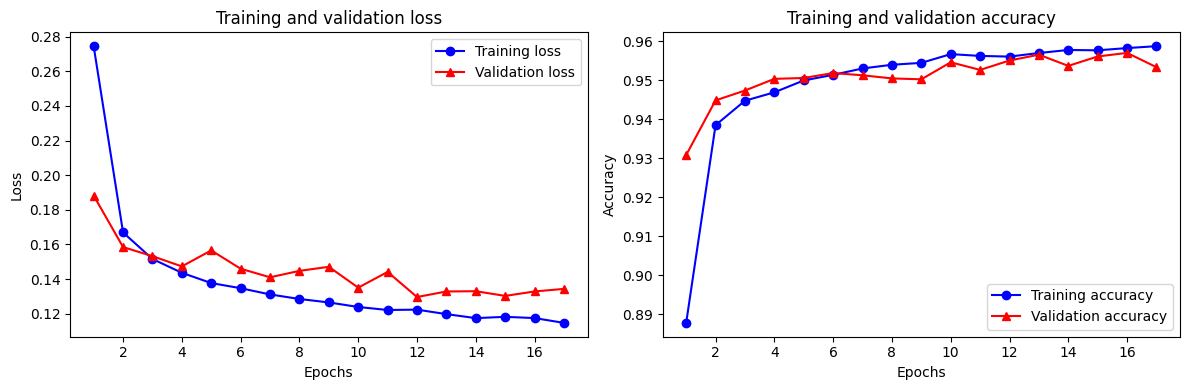

In [ ]:
epochs_range = range(1, len(train_loss_history) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, train_loss_history, "bo-", label="Training loss")
axes[0].plot(epochs_range, val_loss_history, "r^-", label="Validation loss")
axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs_range, train_acc_history, "bo-", label="Training accuracy")
axes[1].plot(epochs_range, val_acc_history, "r^-", label="Validation accuracy")
axes[1].set_title("Training and validation accuracy")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
best_model = PhishingMLP().to(device)
best_model.load_state_dict(torch.load(best_model_path, map_location=device))
best_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        preds = best_model(x).argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(y)

all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

test_acc = (all_preds == all_labels).mean()
print(f"Test accuracy: {100 * test_acc:.2f}%\n")
print("Classification report:")
print(classification_report(all_labels, all_preds, digits=4), "\n")
print("Confusion matrix:")
print(confusion_matrix(all_labels, all_preds))

Test accuracy: 95.08%

Classification report:
              precision    recall  f1-score   support

           0     0.9614    0.9747    0.9680      8302
           1     0.9149    0.8741    0.8940      2582

    accuracy                         0.9508     10884
   macro avg     0.9381    0.9244    0.9310     10884
weighted avg     0.9504    0.9508    0.9505     10884
 

Confusion matrix:
[[8092  210]
 [ 325 2257]]


Результати класичних алгоритмів машинного навчання

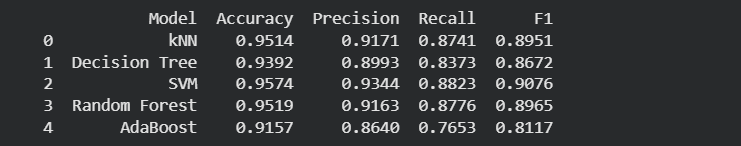

Завдання 2

In [ ]:
import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/cards/card_data.zip"
LOCAL_DIR = "/content/cards_data"

if not os.path.isdir(LOCAL_DIR):
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(LOCAL_DIR)

TRAIN_DIR = f"{LOCAL_DIR}/train"
VAL_DIR = f"{LOCAL_DIR}/valid"
TEST_DIR = f"{LOCAL_DIR}/test"

BATCH_SIZE = 64
N_EPOCHS = 30
PATIENCE = 4
FRACTIONS = [0.1, 0.25, 0.5, 1.0]

In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_set = datasets.ImageFolder(TRAIN_DIR, transform=tf)
val_set = datasets.ImageFolder(VAL_DIR, transform=tf)
test_set = datasets.ImageFolder(TEST_DIR, transform=tf)

num_classes = len(train_set.classes)
print("Classes:", num_classes)
print(f"Train: {len(train_set)}\nVal: {len(val_set)}\nTest: {len(test_set)}")

Classes: 53
Train/Val/Test: 7624 265 265


In [ ]:
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, num_workers=2)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, num_workers=2)

def make_train_loader(fraction):
    if fraction >= 1.0:
        subset = train_set
    else:
        idx, _ = train_test_split(
            np.arange(len(train_set)),
            train_size=fraction,
            stratify=train_set.targets,
            random_state=42,
        )
        subset = Subset(train_set, idx)
    return DataLoader(subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

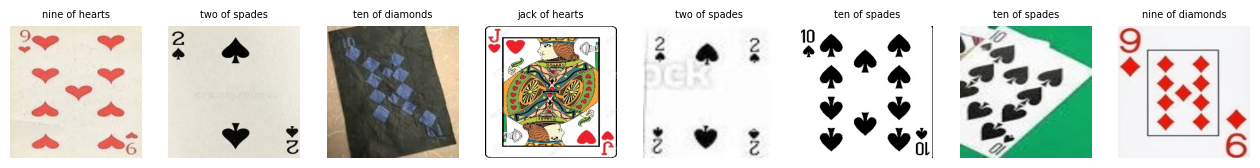

In [ ]:
def show_batch(dataset, n=8):
    idx = torch.randperm(len(dataset))[:n]
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.5))
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    for ax, i in zip(axes, idx):
        img, label = dataset[i]
        img = (img * std + mean).clamp(0, 1)
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(dataset.classes[label], fontsize=7)
        ax.axis("off")
    plt.show()

show_batch(train_set)

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.adapt = nn.AdaptiveAvgPool2d((4, 4))
        self.drop = nn.Dropout(0.3)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.adapt(x)
        x = torch.flatten(x, 1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

def build_pretrained(num_classes):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    for p in model.features.parameters():
        p.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train:
                optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item()
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    return total_loss / len(loader), correct / total

In [ ]:
def fit(model, train_loader, name, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad], lr=lr
    )

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_state, no_improve = float("inf"), None, 0
    start = time.time()

    for epoch in range(N_EPOCHS):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)

        hist["train_loss"].append(tr_loss)
        hist["val_loss"].append(va_loss)
        hist["train_acc"].append(tr_acc)
        hist["val_acc"].append(va_acc)
        print(f"[{name}] [{epoch+1:02d}] train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} | "
              f"val_loss={va_loss:.4f} val_acc={va_acc:.4f}")

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= PATIENCE:
                print(f"[{name}] Early stopping at epoch {epoch+1}")
                break

    hist["time_sec"] = time.time() - start
    hist["best_epoch"] = int(np.argmin(hist["val_loss"])) + 1
    hist["epochs_to_90"] = next(
        (i + 1 for i, a in enumerate(hist["val_acc"]) if a >= 0.9), None
    )

    model.load_state_dict(best_state)
    return hist, model

In [ ]:
@torch.no_grad()
def evaluate_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        total += y.size(0)
    return correct / total

In [ ]:
builders = {
    "CNN from scratch": lambda: SimpleCNN(num_classes),
    "MobileNetV2 (pretrained)": lambda: build_pretrained(num_classes),
}

results = {}

for frac in FRACTIONS:
    loader = make_train_loader(frac)
    n_train = len(loader.dataset)
    for name, build in builders.items():
        print(f"\n===== {name} | train fraction = {frac} ({n_train} images) =====")
        torch.manual_seed(42)
        model = build()
        total, trainable = count_params(model)
        print(f"Params: total={total:,} | trainable={trainable:,}")

        hist, best_model = fit(model, loader, name)
        test_acc = evaluate_accuracy(best_model, test_loader)
        print(f"[{name}] frac={frac} Test accuracy: {100 * test_acc:.2f}%")

        results[(name, frac)] = {"hist": hist, "test_acc": test_acc}


===== CNN from scratch | train fraction = 0.1 (762 images) =====
Params: total=631,861 | trainable=631,861
[CNN from scratch] [01] train_loss=3.9814 train_acc=0.0276 | val_loss=3.8004 val_acc=0.0792
[CNN from scratch] [02] train_loss=3.6669 train_acc=0.0512 | val_loss=3.5932 val_acc=0.0755
[CNN from scratch] [03] train_loss=3.4251 train_acc=0.0984 | val_loss=3.3343 val_acc=0.1132
[CNN from scratch] [04] train_loss=3.2669 train_acc=0.0971 | val_loss=3.1786 val_acc=0.0981
[CNN from scratch] [05] train_loss=3.0737 train_acc=0.1837 | val_loss=3.1560 val_acc=0.1057
[CNN from scratch] [06] train_loss=2.9353 train_acc=0.1745 | val_loss=3.0778 val_acc=0.1321
[CNN from scratch] [07] train_loss=2.8217 train_acc=0.2008 | val_loss=3.0860 val_acc=0.1358
[CNN from scratch] [08] train_loss=2.6982 train_acc=0.2192 | val_loss=2.9693 val_acc=0.1509
[CNN from scratch] [09] train_loss=2.6316 train_acc=0.2349 | val_loss=2.8997 val_acc=0.1396
[CNN from scratch] [10] train_loss=2.4827 train_acc=0.2703 | val

100%|██████████| 13.6M/13.6M [00:00<00:00, 65.1MB/s]

Params: total=2,291,765 | trainable=67,893


[MobileNetV2 (pretrained)] [01] train_loss=3.9204 train_acc=0.0289 | val_loss=3.7153 val_acc=0.0679
[MobileNetV2 (pretrained)] [02] train_loss=3.4037 train_acc=0.2467 | val_loss=3.4320 val_acc=0.1321
[MobileNetV2 (pretrained)] [03] train_loss=3.0332 train_acc=0.4528 | val_loss=3.2914 val_acc=0.1472
[MobileNetV2 (pretrained)] [04] train_loss=2.6964 train_acc=0.6181 | val_loss=3.1795 val_acc=0.1774
[MobileNetV2 (pretrained)] [05] train_loss=2.4338 train_acc=0.6811 | val_loss=3.1019 val_acc=0.1962
[MobileNetV2 (pretrained)] [06] train_loss=2.1879 train_acc=0.7375 | val_loss=3.0264 val_acc=0.2189
[MobileNetV2 (pretrained)] [07] train_loss=1.9828 train_acc=0.7756 | val_loss=2.9881 val_acc=0.2340
[MobileNetV2 (pretrained)] [08] train_loss=1.8286 train_acc=0.8150 | val_loss=2.9575 val_acc=0.2302
[MobileNetV2 (pretrained)] [09] train_loss=1.6371 train_acc=0.8675 | val_loss=2.8910 val_acc=0.2226
[MobileNetV2 (pretrained)] [10] train_loss=1.5263 train_acc=0.8648 | val_loss=2.8876 val_acc=0.2453


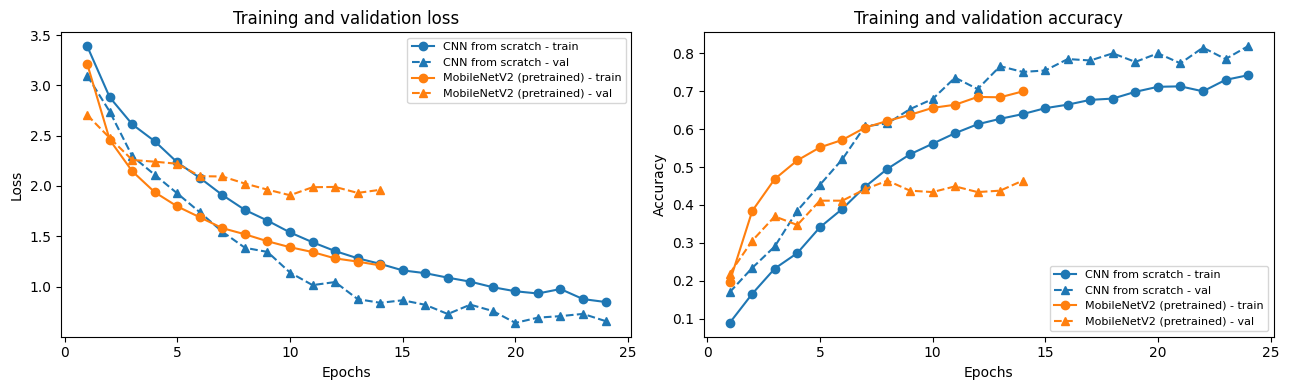

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, color in zip(builders, ["tab:blue", "tab:orange"]):
    h = results[(name, 1.0)]["hist"]
    ep = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(ep, h["train_loss"], "-o", color=color, label=f"{name} - train")
    axes[0].plot(ep, h["val_loss"], "--^", color=color, label=f"{name} - val")
    axes[1].plot(ep, h["train_acc"], "-o", color=color, label=f"{name} - train")
    axes[1].plot(ep, h["val_acc"], "--^", color=color, label=f"{name} - val")

axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
axes[1].set_title("Training and validation accuracy")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

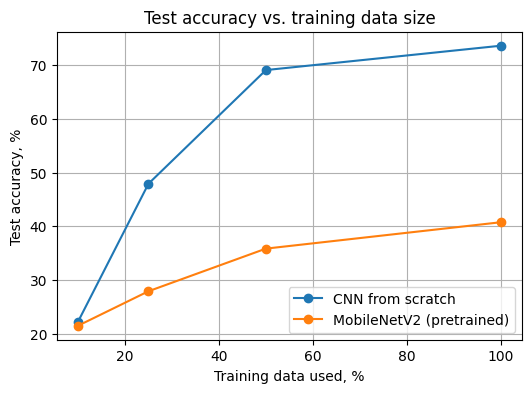

In [ ]:
plt.figure(figsize=(6, 4))
for name in builders:
    accs = [100 * results[(name, f)]["test_acc"] for f in FRACTIONS]
    plt.plot([int(f * 100) for f in FRACTIONS], accs, "-o", label=name)
plt.title("Test accuracy vs. training data size")
plt.xlabel("Training data used, %")
plt.ylabel("Test accuracy, %")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("\n{:<26}{:>7}{:>11}{:>12}{:>13}{:>10}".format(
    "Model", "Frac", "Test acc,%", "Best epoch", "Epochs run", "Time, s"))
for frac in FRACTIONS:
    for name in builders:
        r = results[(name, frac)]
        h = r["hist"]
        print("{:<26}{:>7}{:>11.2f}{:>12}{:>13}{:>10.0f}".format(name, frac, 100 * r["test_acc"], h["best_epoch"], len(h["train_loss"]), h["time_sec"]))


Model                        Frac Test acc,%  Best epoch   Epochs run   Time, s
CNN from scratch              0.1      22.26          21           25        76
MobileNetV2 (pretrained)      0.1      21.51          18           22        57
CNN from scratch             0.25      47.92          29           30       187
MobileNetV2 (pretrained)     0.25      27.92          19           23       134
CNN from scratch              0.5      69.06          28           30       352
MobileNetV2 (pretrained)      0.5      35.85          16           20       195
CNN from scratch              1.0      73.58          20           24       496
MobileNetV2 (pretrained)      1.0      40.75          10           14       287


Завдання 3

In [ ]:
df = pd.read_csv("spam_data.csv", encoding="latin-1")
df = df[["Category", "Message"]]
df = df.rename(columns={
    "Category": "label",
    "Message": "text"
})

df = df.dropna(subset=["text", "label"])
df = df[
    (df["text"].astype(str).str.strip() != "") &
    (df["label"].astype(str).str.strip() != "")
].copy()

df["label"] = df["label"].str.strip().str.lower().map({
    "ham": 0,
    "spam": 1
})
df = df.dropna(subset=["label"]).copy()
print("Shape:", df.shape)

text_raw = df["text"].astype(str)
labels = df["label"].astype(int).values

print("\nРозподіл класів:\n", pd.Series(labels).value_counts())

Shape: (5572, 2)

Розподіл класів:
 0    4825
1     747
Name: count, dtype: int64


In [ ]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text):
    return text.split()

tokens_all = [tokenize(clean_text(t)) for t in text_raw]
print("Приклад токенів:", tokens_all[0][:20])

lens = np.array([len(t) for t in tokens_all])
print(f"Середня довжина листа: {lens.mean():.0f} токенів, медіана: {np.median(lens):.0f}")

Приклад токенів: ['go', 'until', 'jurong', 'point', 'crazy', 'available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'there', 'got', 'amore', 'wat']
Середня довжина листа: 16 токенів, медіана: 12


In [ ]:
idx = np.arange(len(tokens_all))
idx_trainval, idx_test = train_test_split(
    idx, test_size=0.2, random_state=42, stratify=labels
)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=0.2, random_state=42, stratify=labels[idx_trainval]
)
print("Train/Val/Test:", len(idx_train), len(idx_val), len(idx_test))

Train/Val/Test: 3565 892 1115


In [ ]:
counter = Counter()
for i in idx_train:
    counter.update(tokens_all[i])
print(f"Унікальних слів у train: {len(counter):,}")

MAX_VOCAB = 20_000
specials = ["[PAD]", "[UNK]"]
most_common = counter.most_common(MAX_VOCAB - len(specials))
itos = specials + [w for w, _ in most_common]
stoi = {w: i for i, w in enumerate(itos)}

PAD_IDX = stoi["[PAD]"]
UNK_IDX = stoi["[UNK]"]
vocab_size = len(stoi)
print("Розмір словника:", vocab_size)

Унікальних слів у train: 6,067
Розмір словника: 6069


In [ ]:
MAX_LEN = 200
BATCH_SIZE = 128

def encode_and_pad(token_lists):
    arr = np.full((len(token_lists), MAX_LEN), PAD_IDX, dtype=np.int64)
    for row, toks in enumerate(token_lists):
        ids = [stoi.get(t, UNK_IDX) for t in toks[:MAX_LEN]]
        arr[row, :len(ids)] = ids
    return torch.tensor(arr, dtype=torch.long)

def make_loader(indices, shuffle):
    X = encode_and_pad([tokens_all[i] for i in indices])
    y = torch.tensor(labels[indices], dtype=torch.float32)
    return DataLoader(TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = make_loader(idx_train, shuffle=True)
val_loader = make_loader(idx_val, shuffle=False)
test_loader = make_loader(idx_test, shuffle=False)

xb, yb = next(iter(train_loader))
print("Батч:", xb.shape, yb.shape)

Батч: torch.Size([128, 200]) torch.Size([128])


In [ ]:
class TextRNN(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, pad_idx, rnn_type="LSTM", pretrained=None, freeze=True):
        super().__init__()
        if pretrained is not None:
            self.embedding = nn.Embedding.from_pretrained(
                pretrained, freeze=freeze, padding_idx=pad_idx
            )
        else:
            self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)

        rnn_cls = {"LSTM": nn.LSTM, "GRU": nn.GRU, "RNN": nn.RNN}[rnn_type]
        self.rnn = rnn_cls(emb_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, 1)
        self.pad_idx = pad_idx

    def forward(self, x):
        lengths = (x != self.pad_idx).sum(1).clamp(min=1).cpu()
        emb = self.embedding(x)
        packed = nn.utils.rnn.pack_padded_sequence(
            emb, lengths, batch_first=True, enforce_sorted=False
        )
        _, hidden = self.rnn(packed)
        h = hidden[0] if isinstance(hidden, tuple) else hidden
        h_cat = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(h_cat).squeeze(1)

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train:
                optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item()
            correct += ((logits > 0).float() == y).sum().item()
            total += y.size(0)
    return total_loss / len(loader), correct / total

def fit(model, name, lr=1e-3, n_epochs=20, patience=3):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad], lr=lr
    )

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_state, no_improve = float("inf"), None, 0
    start = time.time()

    for epoch in range(n_epochs):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)

        hist["train_loss"].append(tr_loss)
        hist["val_loss"].append(va_loss)
        hist["train_acc"].append(tr_acc)
        hist["val_acc"].append(va_acc)
        print(f"[{name}] [{epoch+1:02d}] train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} | "
              f"val_loss={va_loss:.4f} val_acc={va_acc:.4f}")

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"[{name}] Early stopping at epoch {epoch+1}")
                break

    hist["time_sec"] = time.time() - start
    hist["best_epoch"] = int(np.argmin(hist["val_loss"])) + 1
    model.load_state_dict(best_state)
    return hist, model

In [ ]:
@torch.no_grad()
def evaluate_test(model, name):
    model.eval()
    criterion = nn.BCEWithLogitsLoss()
    all_preds, all_labels, total_loss = [], [], 0.0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += criterion(logits, y).item()
        all_preds.append((logits > 0).long().cpu())
        all_labels.append(y.long().cpu())
    preds = torch.cat(all_preds).numpy()
    true = torch.cat(all_labels).numpy()
    acc = (preds == true).mean()
    print(f"\n[{name}] TEST loss={total_loss / len(test_loader):.4f} acc={100 * acc:.2f}%")
    print(classification_report(true, preds, digits=4))
    return acc

In [ ]:
EMB_DIM = 100
HIDDEN_DIM = 64
RNN_TYPE = "LSTM"

torch.manual_seed(42)
model_rand = TextRNN(vocab_size, EMB_DIM, HIDDEN_DIM, PAD_IDX, rnn_type=RNN_TYPE)
print(model_rand)
total = sum(p.numel() for p in model_rand.parameters())
trainable = sum(p.numel() for p in model_rand.parameters() if p.requires_grad)
print(f"Params: total={total:,} | trainable={trainable:,}")

hist_rand, model_rand = fit(model_rand, "Random emb")
acc_rand = evaluate_test(model_rand, "Random emb")

TextRNN(
  (embedding): Embedding(6069, 100, padding_idx=0)
  (rnn): LSTM(100, 64, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Params: total=692,021 | trainable=692,021
[Random emb] [01] train_loss=0.5266 train_acc=0.8261 | val_loss=0.3346 val_acc=0.8632
[Random emb] [02] train_loss=0.2679 train_acc=0.8813 | val_loss=0.2085 val_acc=0.9114
[Random emb] [03] train_loss=0.1655 train_acc=0.9403 | val_loss=0.1574 val_acc=0.9552
[Random emb] [04] train_loss=0.1044 train_acc=0.9736 | val_loss=0.1356 val_acc=0.9675
[Random emb] [05] train_loss=0.0592 train_acc=0.9888 | val_loss=0.1165 val_acc=0.9664
[Random emb] [06] train_loss=0.0331 train_acc=0.9941 | val_loss=0.1086 val_acc=0.9686
[Random emb] [07] train_loss=0.0204 train_acc=0.9964 | val_loss=0.1070 val_acc=0.9731
[Random emb] [08] train_loss=0.0131 train_acc=0.9983 | val_loss=0.1062 val_acc=0.9742
[Random emb] [09] train_loss=0.0085 train_acc=0.9986 | val_loss=0.1112 val_acc=0.9742
[R

In [ ]:
GLOVE_PATH = "glove.6B.100d.txt"

def load_glove_txt(path):
    vectors = {}
    with open(path, "r", encoding="utf8") as f:
        for line in f:
            parts = line.rstrip().split(" ")
            vectors[parts[0]] = np.asarray(parts[1:], dtype=np.float32)
    return vectors

glove = load_glove_txt(GLOVE_PATH)
print("GloVe entries:", len(glove))
for w in ["the", "email", "bank", "password"]:
    if w in glove:
        print(w, glove[w][:5])

GloVe entries: 400000
the [-0.038194 -0.24487   0.72812  -0.39961   0.083172]
email [-0.57792 -0.16606 -0.17226 -0.87941  0.30588]
bank [ 0.41869  -0.92211   0.048684  0.11798   0.22062 ]
password [-0.57928  -0.52561   1.2608   -0.30475  -0.021845]


In [ ]:
emb_matrix = np.random.normal(scale=0.1, size=(vocab_size, EMB_DIM)).astype(np.float32)
emb_matrix[PAD_IDX] = 0.0

hit = 0
for w, i in stoi.items():
    v = glove.get(w)
    if v is not None:
        emb_matrix[i] = v
        hit += 1
print(f"Coverage: {hit}/{vocab_size} = {hit / vocab_size:.1%}")

FREEZE_GLOVE = True

torch.manual_seed(42)
model_glove = TextRNN(
    vocab_size, EMB_DIM, HIDDEN_DIM, PAD_IDX, rnn_type=RNN_TYPE,
    pretrained=torch.tensor(emb_matrix), freeze=FREEZE_GLOVE,
)
total = sum(p.numel() for p in model_glove.parameters())
trainable = sum(p.numel() for p in model_glove.parameters() if p.requires_grad)
print(f"Params: total={total:,} | trainable={trainable:,}")

hist_glove, model_glove = fit(model_glove, "GloVe emb")
acc_glove = evaluate_test(model_glove, "GloVe emb")

Coverage: 5138/6069 = 84.7%
Params: total=692,021 | trainable=85,121
[GloVe emb] [01] train_loss=0.4229 train_acc=0.8496 | val_loss=0.3240 val_acc=0.8655
[GloVe emb] [02] train_loss=0.2703 train_acc=0.8777 | val_loss=0.2008 val_acc=0.9316
[GloVe emb] [03] train_loss=0.1426 train_acc=0.9568 | val_loss=0.1395 val_acc=0.9540
[GloVe emb] [04] train_loss=0.0912 train_acc=0.9728 | val_loss=0.1171 val_acc=0.9563
[GloVe emb] [05] train_loss=0.0731 train_acc=0.9767 | val_loss=0.1324 val_acc=0.9585
[GloVe emb] [06] train_loss=0.0697 train_acc=0.9801 | val_loss=0.1073 val_acc=0.9664
[GloVe emb] [07] train_loss=0.0541 train_acc=0.9849 | val_loss=0.0988 val_acc=0.9720
[GloVe emb] [08] train_loss=0.0525 train_acc=0.9851 | val_loss=0.0899 val_acc=0.9709
[GloVe emb] [09] train_loss=0.0432 train_acc=0.9899 | val_loss=0.0907 val_acc=0.9731
[GloVe emb] [10] train_loss=0.0427 train_acc=0.9885 | val_loss=0.0969 val_acc=0.9709
[GloVe emb] [11] train_loss=0.0356 train_acc=0.9907 | val_loss=0.0839 val_acc=0.9

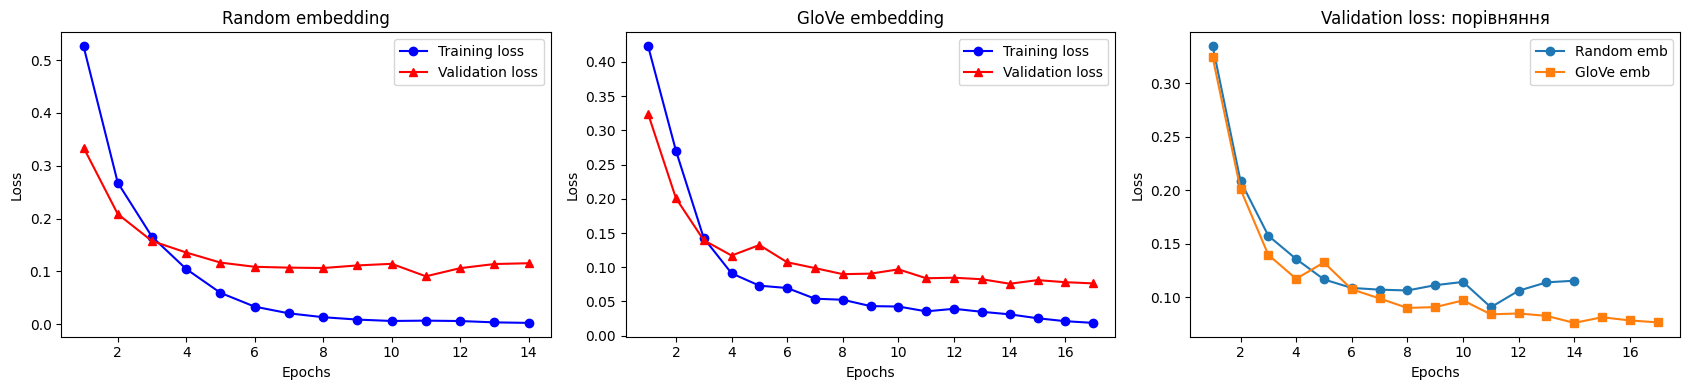

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for ax, hist, title in [
    (axes[0], hist_rand, "Random embedding"),
    (axes[1], hist_glove, "GloVe embedding"),
]:
    ep = range(1, len(hist["train_loss"]) + 1)
    ax.plot(ep, hist["train_loss"], "bo-", label="Training loss")
    ax.plot(ep, hist["val_loss"], "r^-", label="Validation loss")
    ax.set_title(title)
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Loss")
    ax.legend()

ep_r = range(1, len(hist_rand["val_loss"]) + 1)
ep_g = range(1, len(hist_glove["val_loss"]) + 1)
axes[2].plot(ep_r, hist_rand["val_loss"], "o-", label="Random emb")
axes[2].plot(ep_g, hist_glove["val_loss"], "s-", label="GloVe emb")
axes[2].set_title("Validation loss: порівняння")
axes[2].set_xlabel("Epochs")
axes[2].set_ylabel("Loss")
axes[2].legend()

plt.tight_layout()
plt.show()

In [ ]:
print("{:<14}{:>12}{:>13}{:>13}{:>10}".format("Model", "Test acc,%", "Best epoch", "Epochs run", "Time, s"))
for name, hist, acc in [("Random emb", hist_rand, acc_rand), ("GloVe emb", hist_glove, acc_glove)]:
    print("{:<14}{:>12.2f}{:>13}{:>13}{:>10.0f}".format(name, 100 * acc, hist["best_epoch"], len(hist["train_loss"]), hist["time_sec"]))

Model           Test acc,%   Best epoch   Epochs run   Time, s
Random emb           98.30           11           14         5
GloVe emb            97.31           14           17         7
